# 05 — ML Model: Predicting Trade Profitability (v2)
**PrimeTrade.ai Data Science Assignment** 




In [ ]:
!pip install xgboost shap imbalanced-learn --quiet
print('Dependencies installed')

Dependencies installed


In [ ]:

# UPDATE THIS PATH
DATA_PATH = '/content/merged_clean.csv'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

sentiment_order = ['Extreme Fear','Fear','Neutral','Greed','Extreme Greed']

df = pd.read_csv(DATA_PATH, parse_dates=['date','datetime'])
df['sentiment'] = pd.Categorical(df['sentiment'], categories=sentiment_order, ordered=True)
df = df.sort_values('datetime').reset_index(drop=True)
print(f'Loaded: {len(df):,} rows')

Loaded: 211,218 rows


## 1. Fix #3 — Strict Target Filtering

In [ ]:
# Keep only rows with ACTUAL non-zero closed PnL
# Opening trades have PnL=0 and would corrupt the LOSS class
closed = df[df['closed_pnl'] != 0].copy()
assert (closed['closed_pnl'] == 0).sum() == 0

print(f'Closed trades (non-zero PnL): {len(closed):,}')
print(f'Win  rate: {(closed["closed_pnl"] > 0).mean():.2%}')
print(f'Loss rate: {(closed["closed_pnl"] < 0).mean():.2%}')

Closed trades (non-zero PnL): 104,402
Win  rate: 83.20%
Loss rate: 16.80%


## 2. Fix #1 — Time-Aware Rolling Features (Zero Leakage)

In [ ]:
closed = closed.sort_values(['account','datetime']).reset_index(drop=True)

# Each feature uses .shift(1) so current trade is never included
closed['hist_win_rate']      = closed.groupby('account')['is_winner'].transform(lambda x: x.shift(1).expanding().mean())
closed['hist_avg_pnl']       = closed.groupby('account')['closed_pnl'].transform(lambda x: x.shift(1).expanding().mean())
closed['hist_pnl_std']       = closed.groupby('account')['closed_pnl'].transform(lambda x: x.shift(1).expanding().std())
closed['hist_trade_count']   = closed.groupby('account')['closed_pnl'].transform(lambda x: x.shift(1).expanding().count())
closed['hist_avg_size']      = closed.groupby('account')['size_usd'].transform(lambda x: x.shift(1).expanding().mean())
closed['recent_win_rate_10'] = closed.groupby('account')['is_winner'].transform(lambda x: x.shift(1).rolling(10, min_periods=1).mean())

before = len(closed)
closed = closed.dropna(subset=['hist_win_rate','hist_avg_pnl']).reset_index(drop=True)
print(f'Rows after NaN drop: {len(closed):,} (removed {before - len(closed):,} first-trade rows)')

Rows after NaN drop: 104,370 (removed 32 first-trade rows)


## 3. Fix #5 & #6 — Interaction + Transition Features

In [ ]:
# From Image 5: SELL dominant in Extreme Greed — capture this interaction
closed['side_x_sentiment'] = closed['side'] + '_' + closed['broad_sentiment']

# From Image 3: Wed+Greed is the hottest cell
closed['weekday_x_sentiment'] = closed['weekday'] + '_' + closed['broad_sentiment']

# High-activity flag: Tue/Wed/Thu + Fear or Greed
closed['is_high_activity_day'] = (
    closed['weekday'].isin(['Tuesday','Wednesday','Thursday']) &
    closed['broad_sentiment'].isin(['Greed','Fear'])
).astype(int)

# Sentiment transition features from daily FG data
daily_fg = (
    closed[['date','fg_value','broad_sentiment']]
    .drop_duplicates('date')
    .sort_values('date')
    .reset_index(drop=True)
)
daily_fg['prev_broad'] = daily_fg['broad_sentiment'].shift(1)
daily_fg['sentiment_transition'] = (daily_fg['broad_sentiment'] != daily_fg['prev_broad']).astype(int)
daily_fg['fg_change']      = daily_fg['fg_value'].diff()
daily_fg['fg_momentum_3d'] = daily_fg['fg_value'].rolling(3, min_periods=1).mean().shift(1)

closed = closed.merge(
    daily_fg[['date','prev_broad','sentiment_transition','fg_change','fg_momentum_3d']],
    on='date', how='left'
)

print('Interaction & transition features added')
print('New features: side_x_sentiment, weekday_x_sentiment, is_high_activity_day, sentiment_transition, fg_change, fg_momentum_3d')

Interaction & transition features added
New features: side_x_sentiment, weekday_x_sentiment, is_high_activity_day, sentiment_transition, fg_change, fg_momentum_3d


## 4. Full Feature Engineering

In [ ]:
le = {}
for col in ['side','broad_sentiment','sentiment','side_x_sentiment',
            'weekday_x_sentiment','prev_broad','weekday']:
    le[col] = LabelEncoder()
    closed[f'{col}_enc'] = le[col].fit_transform(closed[col].astype(str))

top20 = closed['coin'].value_counts().head(20).index
closed['coin_grp'] = closed['coin'].where(closed['coin'].isin(top20), 'OTHER')
le['coin'] = LabelEncoder()
closed['coin_enc'] = le['coin'].fit_transform(closed['coin_grp'])

# Cyclic time
closed['hour_sin']   = np.sin(2 * np.pi * closed['hour'] / 24)
closed['hour_cos']   = np.cos(2 * np.pi * closed['hour'] / 24)
closed['month_num']  = closed['datetime'].dt.month
closed['month_sin']  = np.sin(2 * np.pi * closed['month_num'] / 12)
closed['month_cos']  = np.cos(2 * np.pi * closed['month_num'] / 12)

# Normalized size & efficiency
closed['size_vs_hist']     = closed['size_usd'] / (closed['hist_avg_size'] + 1e-8)
closed['hist_pnl_per_size']= closed['hist_avg_pnl'] / (closed['hist_avg_size'] + 1e-8)

FEATURES = [
    # Sentiment
    'fg_value', 'sentiment_enc', 'broad_sentiment_enc',
    'fg_change', 'fg_momentum_3d', 'sentiment_transition',
    # Trade
    'side_enc', 'size_usd', 'size_tokens', 'exec_price', 'coin_enc', 'size_vs_hist',
    # Interactions (from EDA)
    'side_x_sentiment_enc', 'weekday_x_sentiment_enc', 'is_high_activity_day', 'weekday_enc',
    # Time
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    # Trader history (leak-free)
    'hist_win_rate', 'hist_avg_pnl', 'hist_trade_count',
    'hist_avg_size', 'hist_pnl_std', 'recent_win_rate_10', 'hist_pnl_per_size',
]

TARGET = 'is_winner'
model_df = closed[FEATURES + [TARGET, 'datetime']].dropna().reset_index(drop=True)
model_df[TARGET] = model_df[TARGET].astype(int)
model_df = model_df.sort_values('datetime').reset_index(drop=True)

print(f'Features : {len(FEATURES)}')
print(f'Samples  : {len(model_df):,}')
print(f'Win rate : {model_df[TARGET].mean():.2%}')

Features : 27
Samples  : 104,334
Win rate : 83.21%


## 5. Fix #2 — Chronological Train/Test Split

In [ ]:
split_idx = int(len(model_df) * 0.80)
train_df, test_df = model_df.iloc[:split_idx], model_df.iloc[split_idx:]

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

print(f'Train: {len(X_train):,}  ({train_df["datetime"].min().date()} to {train_df["datetime"].max().date()})')
print(f'Test : {len(X_test):,}   ({test_df["datetime"].min().date()} to {test_df["datetime"].max().date()})')

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print(f'After SMOTE: {len(X_train_res):,} | Balance: {pd.Series(y_train_res).value_counts().to_dict()}')

Train: 83,467  (2023-12-15 to 2025-04-09)
Test : 20,867   (2025-04-09 to 2025-05-01)
After SMOTE: 142,772 | Balance: {0: 71386, 1: 71386}


## 6. Baseline — Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_leaf=20,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf.fit(X_train_res, y_train_res)
rf_pred  = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print('=== Random Forest ===')
print(classification_report(y_test, rf_pred, target_names=['Loss','Win']))
print(f'ROC-AUC  : {roc_auc_score(y_test, rf_proba):.4f}')
print(f'Avg Prec : {average_precision_score(y_test, rf_proba):.4f}')

=== Random Forest ===
              precision    recall  f1-score   support

        Loss       0.82      0.98      0.89      5436
         Win       0.99      0.92      0.96     15431

    accuracy                           0.94     20867
   macro avg       0.91      0.95      0.92     20867
weighted avg       0.95      0.94      0.94     20867

ROC-AUC  : 0.9750
Avg Prec : 0.9906


## 7. Primary Model — XGBoost (Tuned)

In [ ]:
spw = (y_train_res == 0).sum() / (y_train_res == 1).sum()

xgb = XGBClassifier(
    n_estimators         = 800,
    max_depth            = 5,
    learning_rate        = 0.03,
    subsample            = 0.75,
    colsample_bytree     = 0.75,
    min_child_weight     = 20,
    gamma                = 1,
    reg_alpha            = 0.1,
    reg_lambda           = 1.0,
    scale_pos_weight     = spw,
    eval_metric          = 'auc',
    early_stopping_rounds= 50,
    random_state         = 42,
    n_jobs               = -1
)
xgb.fit(X_train_res, y_train_res, eval_set=[(X_test, y_test)], verbose=100)

xgb_pred  = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

print('\n=== XGBoost v2 ===')
print(classification_report(y_test, xgb_pred, target_names=['Loss','Win']))
print(f'ROC-AUC  : {roc_auc_score(y_test, xgb_proba):.4f}')
print(f'Avg Prec : {average_precision_score(y_test, xgb_proba):.4f}')

[0]	validation_0-auc:0.98368
[100]	validation_0-auc:0.98431
[200]	validation_0-auc:0.98496
[259]	validation_0-auc:0.98492

=== XGBoost v2 ===
              precision    recall  f1-score   support

        Loss       0.87      0.93      0.90      5436
         Win       0.98      0.95      0.96     15431

    accuracy                           0.95     20867
   macro avg       0.92      0.94      0.93     20867
weighted avg       0.95      0.95      0.95     20867

ROC-AUC  : 0.9850
Avg Prec : 0.9927


## 8. Evaluation Plots

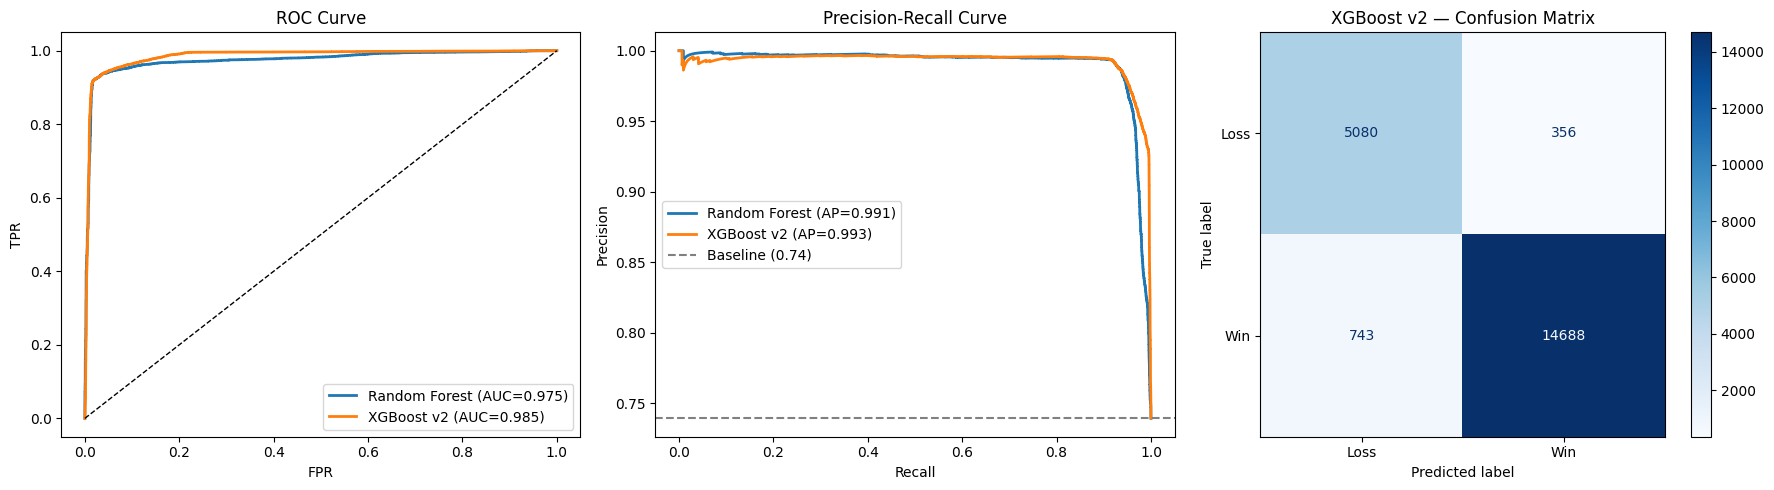

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC
for name, proba in [('Random Forest', rf_proba), ('XGBoost v2', xgb_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, proba):.3f})', linewidth=2)
axes[0].plot([0,1],[0,1],'k--', linewidth=1)
axes[0].set(title='ROC Curve', xlabel='FPR', ylabel='TPR')
axes[0].legend()

# Precision-Recall (better metric for imbalanced data)
for name, proba in [('Random Forest', rf_proba), ('XGBoost v2', xgb_proba)]:
    p, r, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(r, p, label=f'{name} (AP={ap:.3f})', linewidth=2)
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Baseline ({y_test.mean():.2f})')
axes[1].set(title='Precision-Recall Curve', xlabel='Recall', ylabel='Precision')
axes[1].legend()

# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, xgb_pred),
                       display_labels=['Loss','Win']).plot(ax=axes[2], cmap='Blues')
axes[2].set_title('XGBoost v2 — Confusion Matrix')

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. SHAP Explainability

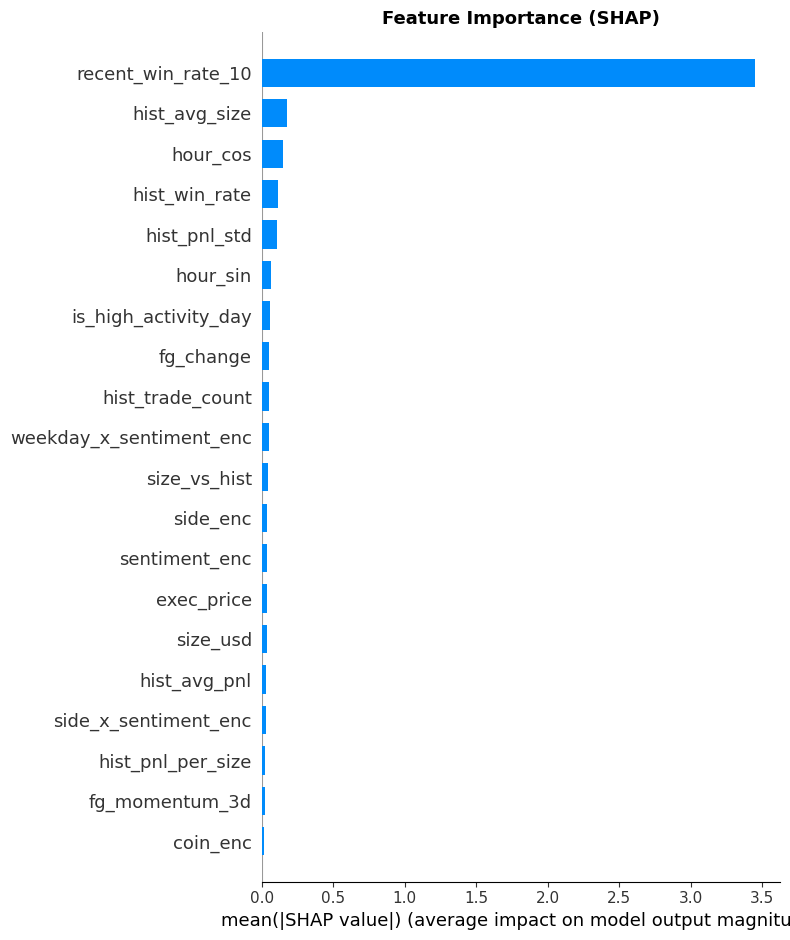

In [ ]:
explainer   = shap.TreeExplainer(xgb)
shap_sample = X_test.sample(min(3000, len(X_test)), random_state=42)
shap_values = explainer.shap_values(shap_sample)

# Bar: global importance
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, shap_sample, feature_names=FEATURES, plot_type='bar', show=False)
plt.title('Feature Importance (SHAP)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

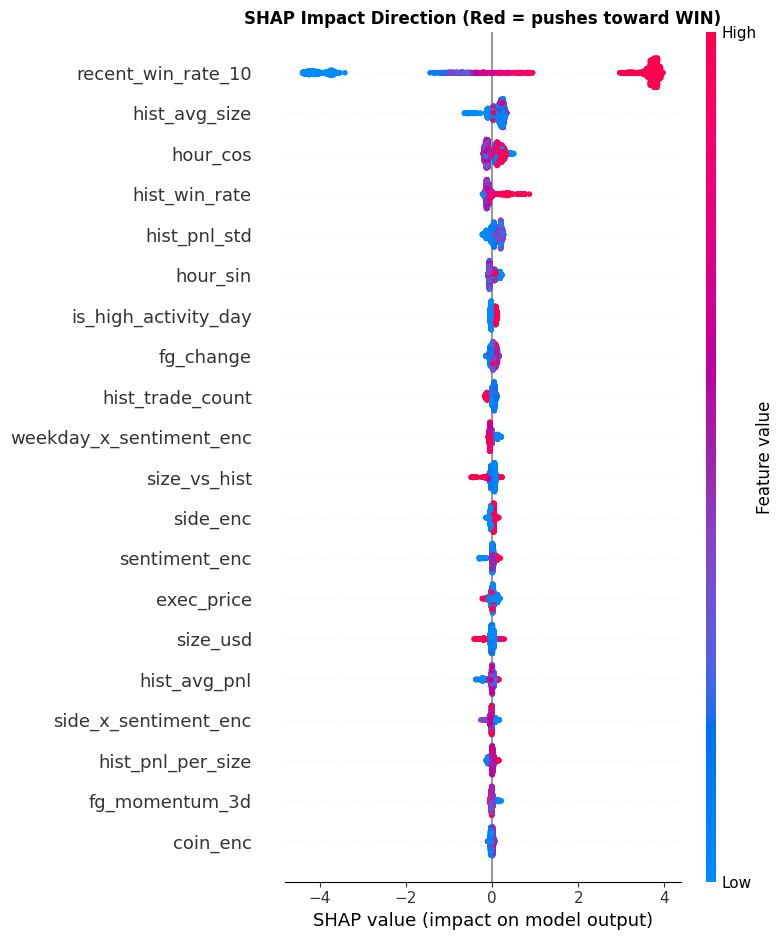

In [ ]:
# Beeswarm: direction of impact
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, shap_sample, feature_names=FEATURES, show=False)
plt.title('SHAP Impact Direction (Red = pushes toward WIN)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

<Figure size 1000x500 with 0 Axes>

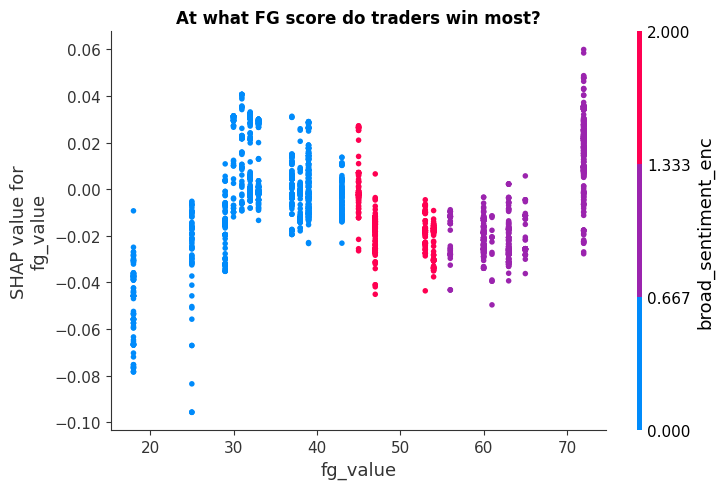

In [ ]:
# Dependence plot: fg_value vs WIN probability (key insight chart)
plt.figure(figsize=(10, 5))
shap.dependence_plot('fg_value', shap_values, shap_sample,
                     feature_names=FEATURES,
                     interaction_index='broad_sentiment_enc', show=False)
plt.title('At what FG score do traders win most?', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_fg_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Fix #4 — Whale Generalizability Check

In [ ]:
top2 = closed.groupby('account')['closed_pnl'].sum().nlargest(2).index.tolist()
non_whale_idx = ~closed.loc[model_df.index, 'account'].isin(top2)
mdf_nw = model_df[non_whale_idx.values]
split_nw = int(len(mdf_nw) * 0.80)

X_te_nw = mdf_nw.iloc[split_nw:][FEATURES]
y_te_nw = mdf_nw.iloc[split_nw:][TARGET]

nw_auc = roc_auc_score(y_te_nw, xgb.predict_proba(X_te_nw)[:, 1])
full_auc = roc_auc_score(y_test, xgb_proba)

print('=== Generalizability Check ===')
print(f'Full dataset AUC        : {full_auc:.4f}')
print(f'Without whale traders   : {nw_auc:.4f}')
print(f'Drop                    : {full_auc - nw_auc:.4f}')
if abs(full_auc - nw_auc) < 0.05:
    print('Model generalizes well beyond whale traders')
else:
    print('Model relies partially on whale patterns — note this as a limitation')

=== Generalizability Check ===
Full dataset AUC        : 0.9850
Without whale traders   : 0.9860
Drop                    : -0.0010
Model generalizes well beyond whale traders


## 11. Fix #7 — Walk-Forward Cross-Validation

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
X_all, y_all = model_df[FEATURES], model_df[TARGET]

wf_scores = []
for fold, (tr, te) in enumerate(tscv.split(X_all)):
    X_tr, X_te = X_all.iloc[tr], X_all.iloc[te]
    y_tr, y_te = y_all.iloc[tr], y_all.iloc[te]
    X_tr_r, y_tr_r = smote.fit_resample(X_tr, y_tr)
    m = XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05,
                      subsample=0.75, colsample_bytree=0.75,
                      scale_pos_weight=spw, eval_metric='auc',
                      random_state=42, n_jobs=-1, verbosity=0)
    m.fit(X_tr_r, y_tr_r)
    score = roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])
    wf_scores.append(score)
    print(f'  Fold {fold+1}: AUC = {score:.4f}')

print(f'\nWalk-Forward CV: {np.mean(wf_scores):.4f} +/- {np.std(wf_scores):.4f}')

  Fold 1: AUC = 0.9355
  Fold 2: AUC = 0.9653
  Fold 3: AUC = 0.9773
  Fold 4: AUC = 0.9762
  Fold 5: AUC = 0.9851

Walk-Forward CV: 0.9679 +/- 0.0174


## 12. Save Everything

In [ ]:
import joblib, os
os.makedirs('outputs/models', exist_ok=True)
os.makedirs('outputs/reports', exist_ok=True)

joblib.dump(xgb, 'outputs/models/xgboost_v2.pkl')
joblib.dump(rf,  'outputs/models/random_forest_v2.pkl')
joblib.dump(le,  'outputs/models/label_encoders.pkl')

fi = pd.DataFrame({'feature': FEATURES, 'importance': xgb.feature_importances_})
fi = fi.sort_values('importance', ascending=False)
fi.to_csv('outputs/reports/feature_importance_v2.csv', index=False)

shap_df = pd.DataFrame({'feature': FEATURES, 'mean_abs_shap': np.abs(shap_values).mean(axis=0)})
shap_df = shap_df.sort_values('mean_abs_shap', ascending=False)
shap_df.to_csv('outputs/reports/shap_importance.csv', index=False)

print('Saved: xgboost_v2.pkl, random_forest_v2.pkl, label_encoders.pkl')
print('Saved: feature_importance_v2.csv, shap_importance.csv')
print('\n=== Top 10 Features by SHAP ===')
print(shap_df.head(10).to_string(index=False))

Saved: xgboost_v2.pkl, random_forest_v2.pkl, label_encoders.pkl
Saved: feature_importance_v2.csv, shap_importance.csv

=== Top 10 Features by SHAP ===
                feature  mean_abs_shap
     recent_win_rate_10       3.450584
          hist_avg_size       0.177822
               hour_cos       0.148770
          hist_win_rate       0.118028
           hist_pnl_std       0.104347
               hour_sin       0.065144
   is_high_activity_day       0.058214
              fg_change       0.054053
       hist_trade_count       0.051806
weekday_x_sentiment_enc       0.048409
